# Lab: GeoPandas — część A
PM2.5 w dzielnicach Opola i przy szkołach podstawowych.

Dane w katalogu `dane/` obok notatnika.

## 0. Sprawdzenie środowiska

In [1]:
import geopandas as gpd
import rasterio
import shapely

print("geopandas", gpd.__version__)
print("rasterio ", rasterio.__version__, "| GDAL", rasterio.__gdal_version__)
print("shapely  ", shapely.__version__)

geopandas 1.2.0
rasterio  1.5.2 | GDAL 3.12.2
shapely   2.2.0


## A1. Geometria i GeoDataFrame od zera

In [2]:
from shapely.geometry import Point, Polygon

rynek = Point(17.9226, 50.6681)          # (x, y) = (longitude, latitude)
square = Polygon([(17.92, 50.66), (17.93, 50.66), (17.93, 50.67), (17.92, 50.67)])

print(rynek)
print(square.area)                       # in "units of the coordinates" - here: square degrees!
print(square.contains(rynek))

POINT (17.9226 50.6681)
0.00010000000000003127
True


In [3]:
places = gpd.GeoDataFrame(
    {"name": ["Rynek", "Square"]},
    geometry=[rynek, square],
    crs="EPSG:4326",                     # WGS 84 - longitude/latitude in degrees
)
places

,name,geometry
0,Rynek,POINT (17.9226 50.6681)
1,Square,"POLYGON ((17.92 50.66, 17.93 50.66, 17.93 50.6..."


In [4]:
print(type(places))
print(places.crs)
print(places.geom_type)

<class 'geopandas.geodataframe.GeoDataFrame'>
EPSG:4326
0      Point
1    Polygon
dtype: str


✅ `places.crs` = EPSG:4326, `geom_type` = Point i Polygon.

## A2. Wczytanie surowych danych

In [5]:
import pandas as pd

raw = pd.read_csv("dane/pm25_sensors.csv", parse_dates=["measured_at"])
print(raw.shape)
raw.head(10)

(145, 5)


,sensor_id,lat,lon,pm25,measured_at
0,PM-042,50.675603,17.906425,23.5,2026-10-01 08:36:00
1,PM-106,50.632283,17.919674,12.4,2026-10-01 08:22:00
2,PM-130,50.635608,18.020378,19.4,2026-10-01 08:24:00
3,PM-006,50.674051,NaN,25.7,2026-10-01 08:03:00
4,PM-025,50.676438,17.938766,16.8,2026-10-01 08:13:00
5,PM-137,17.873510,50.677587,14.4,2026-10-01 08:06:00
6,PM-036,50.666829,17.940071,23.7,2026-10-01 08:23:00
7,PM-100,50.694328,17.802222,12.5,2026-10-01 08:56:00
8,PM-092,50.684393,17.794548,9.3,2026-10-01 08:09:00
9,PM-087,50.650288,17.940259,-999.0,2026-10-01 08:56:00


In [6]:
raw[["lat", "lon", "pm25"]].describe()

,lat,lon,pm25
count,142.000000,141.000000,145.000000
mean,49.980869,18.613736,-8.995172
std,4.727557,4.743171,167.401474
min,17.873510,17.785622,-999.000000
25%,50.652463,17.897319,14.500000
50%,50.669682,17.918011,19.100000
75%,50.686753,17.940870,22.500000
max,50.767895,50.677587,35.300000


In [7]:
raw.isna().sum()

sensor_id      0
lat            3
lon            4
pm25           0
measured_at    0
dtype: int64

In [8]:
raw.duplicated().sum()

np.int64(5)

In [9]:
# punkt kontrolny A2
assert raw.shape == (145, 5)
assert raw["pm25"].min() == -999
assert raw["lat"].isna().sum() == 3 and raw["lon"].isna().sum() == 4
assert raw.duplicated().sum() == 5
print("A2 OK, min lat =", raw["lat"].min())

A2 OK, min lat = 17.87351


In [10]:
# skąd lat ≈ 17,9? -> wiersze z zamienionymi kolumnami
raw[raw["lat"] < 40]

,sensor_id,lat,lon,pm25,measured_at
5,PM-137,17.873510,50.677587,14.4,2026-10-01 08:06:00
61,PM-120,17.947814,50.653409,21.5,2026-10-01 08:22:00
102,PM-080,17.923944,50.673200,28.9,2026-10-01 08:01:00


🤔 **Skąd minimum `lat` ≈ 17,9?** Opole leży na ok. 50,7° N i 17,9° E, więc 17,9 to *długość* geograficzna. W tych wierszach
czujnik (albo firma przy eksporcie) zapisał współrzędne w kolejności (lon, lat) zamiast (lat, lon) — kolumny są zamienione.
Widać to wyżej: w tych samych wierszach `lon` ≈ 50,7.

## A3. Czyszczenie danych

In [11]:
df = raw.copy()
report = {"input rows": len(df)}

# 1. Duplicates - the same message sent twice
df = df.drop_duplicates()
report["after drop_duplicates"] = len(df)

# 2. Rows without coordinates cannot be placed on a map
df = df.dropna(subset=["lat", "lon"])
report["after dropna"] = len(df)

# 3. Swapped coordinates: in Poland lat is 49-55 and lon is 14-24
swapped = df["lat"].between(14, 24.5) & df["lon"].between(49, 55)
df.loc[swapped, ["lat", "lon"]] = df.loc[swapped, ["lon", "lat"]].to_numpy()
report["swapped rows fixed"] = int(swapped.sum())

# 4. -999 is the sensor's error code, not a measurement
df = df[df["pm25"] >= 0].reset_index(drop=True)
report["clean rows"] = len(df)

report

{'input rows': 145,
 'after drop_duplicates': 140,
 'after dropna': 134,
 'swapped rows fixed': 3,
 'clean rows': 130}

In [12]:
df[["lat", "lon", "pm25"]].describe().round(2)

,lat,lon,pm25
count,130.00,130.00,130.00
mean,50.67,17.92,18.86
std,0.03,0.04,5.19
min,50.62,17.79,9.20
25%,50.65,17.90,14.65
50%,50.67,17.92,19.00
75%,50.69,17.94,22.22
max,50.77,18.02,35.30


In [13]:
assert list(report.values()) == [145, 140, 134, 3, 130]
print("A3 OK")

A3 OK


Eksperyment: co się dzieje **bez** `.to_numpy()`:

In [14]:
demo = raw.drop_duplicates().dropna(subset=["lat", "lon"]).copy()
sw = demo["lat"].between(14, 24.5) & demo["lon"].between(49, 55)
print("przed:\n", demo.loc[sw, ["lat", "lon"]])
demo.loc[sw, ["lat", "lon"]] = demo.loc[sw, ["lon", "lat"]]   # bez .to_numpy()
print("po (bez .to_numpy()):\n", demo.loc[sw, ["lat", "lon"]])

przed:
            lat        lon
5    17.873510  50.677587
61   17.947814  50.653409
102  17.923944  50.673200
po (bez .to_numpy()):
            lat        lon
5    17.873510  50.677587
61   17.947814  50.653409
102  17.923944  50.673200


Bez `.to_numpy()` pandas **wyrównuje prawą stronę po etykietach kolumn**: do kolumny `lat` wpisuje wartości z kolumny `lat`,
a do `lon` z `lon`. Zamiana „cofa się” i nic się nie zmienia. `.to_numpy()` zdejmuje etykiety, więc wartości trafiają pozycyjnie.

🤔 **Dlaczego zamienione współrzędne naprawiamy, a -999 usuwamy?** Przy zamienionych współrzędnych żadna informacja nie zginęła,
wszystkie liczby są poprawne, tylko w złych kolumnach, więc da się je jednoznacznie odtworzyć. -999 to kod błędu czujnika:
prawdziwego pomiaru po prostu nie ma i nie da się go odzyskać. Wpisanie czegoś w jego miejsce (0, średnia) byłoby zmyśleniem danych,
a zostawienie -999 rozwaliłoby każdą średnią.

## A4. Z tabeli do GeoDataFrame

In [15]:
sensors = gpd.GeoDataFrame(
    df,
    geometry=gpd.points_from_xy(df["lon"], df["lat"]),   # x = lon, y = lat!
    crs="EPSG:4326",
)
sensors.head()

,sensor_id,lat,lon,pm25,measured_at,geometry
0,PM-042,50.675603,17.906425,23.5,2026-10-01 08:36:00,POINT (17.90642 50.6756)
1,PM-106,50.632283,17.919674,12.4,2026-10-01 08:22:00,POINT (17.91967 50.63228)
2,PM-130,50.635608,18.020378,19.4,2026-10-01 08:24:00,POINT (18.02038 50.63561)
3,PM-025,50.676438,17.938766,16.8,2026-10-01 08:13:00,POINT (17.93877 50.67644)
4,PM-137,50.677587,17.873510,14.4,2026-10-01 08:06:00,POINT (17.87351 50.67759)


In [16]:
print(sensors.geom_type.unique())
print(sensors.crs)
print(sensors.total_bounds)              # [minx, miny, maxx, maxy]

<ArrowStringArray>
['Point']
Length: 1, dtype: str
EPSG:4326
[17.785622 50.616593 18.020378 50.767895]


In [17]:
sensors.explore(column="pm25", cmap="Oranges", marker_kwds={"radius": 6})

In [18]:
# 🤔 zamienione argumenty
wrong = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df["lat"], df["lon"]), crs="EPSG:4326")
print(wrong.total_bounds)
wrong.explore(marker_kwds={"radius": 6})

[50.616593 17.785622 50.767895 18.020378]


🤔 **`points_from_xy(df["lat"], df["lon"])`:** x = 50,7 (długość), y = 17,9 (szerokość). Punkt ląduje ok. 50,7° E i 17,9° N,
czyli na pustyni we **wschodnim Jemenie**, niedaleko granicy z Arabią Saudyjską i Omanem. Cała chmura czujników przenosi się na Półwysep Arabski. GeoPandas nie zgłasza błędu,
bo obie liczby są poprawnymi współrzędnymi. Błąd widać dopiero na mapie.

## A5. Układy współrzędnych

In [19]:
a, b = sensors.geometry.iloc[0], sensors.geometry.iloc[1]
a.distance(b)

0.04530075497163559

In [20]:
sensors_m = sensors.to_crs("EPSG:2180")
sensors_m.geometry.iloc[0].distance(sensors_m.geometry.iloc[1])

4906.147424422837

In [21]:
sensors_m.head(3)[["sensor_id", "geometry"]]

,sensor_id,geometry
0,PM-042,POINT (422754.546 312637.211)
1,PM-106,POINT (423620.153 307808.028)
2,PM-130,POINT (430744.745 308078.679)


In [22]:
from pyproj import Geod

gdansk, zakopane = (18.6466, 54.3520), (19.9496, 49.2992)
pts = gpd.GeoSeries.from_xy([gdansk[0], zakopane[0]], [gdansk[1], zakopane[1]], crs="EPSG:4326")

_, _, true_m = Geod(ellps="WGS84").inv(*gdansk, *zakopane)
print(f"geodesic : {true_m / 1000:8.1f} km")

for crs in ["EPSG:3857", "EPSG:2180"]:
    p = pts.to_crs(crs)
    d = p.iloc[0].distance(p.iloc[1])
    print(f"{crs}: {d / 1000:8.1f} km   error {100 * (d / true_m - 1):+.2f} %")

geodesic :    569.3 km
EPSG:3857:    922.8 km   error +62.09 %
EPSG:2180:    568.9 km   error -0.07 %


Merkator rozciąga odległości o czynnik 1/cos(φ). Dla ok. 52° to ok. 1,62, stąd błąd +62%.
**Zasada:** przechowuj w EPSG:4326, licz w EPSG:2180, wyświetlaj w czym chcesz.

## A6. Poligony: dzielnice Opola

In [23]:
districts = gpd.read_file("dane/opole_districts.geojson")
print(len(districts), districts.crs)
districts.head()

29 EPSG:4326


,osm_id,name,geometry
0,9709955,Armii Krajowej,"POLYGON ((17.94533 50.68232, 17.94712 50.68404..."
1,9710023,Bierkowice,"POLYGON ((17.84376 50.6998, 17.84415 50.69965,..."
2,9710193,Borki,"POLYGON ((17.87562 50.74302, 17.87767 50.74222..."
3,9710322,Brzezie,"POLYGON ((17.88652 50.75983, 17.88756 50.75843..."
4,9711126,Chabry,"POLYGON ((17.92146 50.67526, 17.92164 50.67542..."


In [24]:
# 🤔 .area bez to_crs - w stopniach kwadratowych
import warnings
with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter("always")
    deg_area = districts.area.sum()
print("suma .area w EPSG:4326:", deg_area, "stopni²")
print("ostrzeżenie:", w[0].message if w else None)

suma .area w EPSG:4326: 0.01894979690250007 stopni²
ostrzeżenie: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.



In [25]:
districts = districts.to_crs("EPSG:2180")
districts["area_km2"] = districts.area / 1e6        # m² -> km²

print(f"City area: {districts['area_km2'].sum():.1f} km²")
districts.sort_values("area_km2", ascending=False).head()

City area: 148.8 km²


,osm_id,name,geometry,area_km2
6,9711276,Czarnowąsy,"POLYGON ((420790.396 319539.109, 420754.248 31...",14.116777
10,2732169,Grudzice,"POLYGON ((427076.872 309182.343, 427253.379 30...",12.343554
22,9708643,Wrzoski,"POLYGON ((417245.105 316509.303, 417329.252 31...",11.463066
27,9721684,Świerkle,"POLYGON ((421489.288 322020.575, 422512.041 32...",8.619009
8,2732168,Groszowice,"POLYGON ((427076.872 309182.343, 427186.641 30...",8.023906


In [26]:
districts.nsmallest(1, "area_km2")[["name", "area_km2"]]

,name,area_km2
2,Borki,0.6649


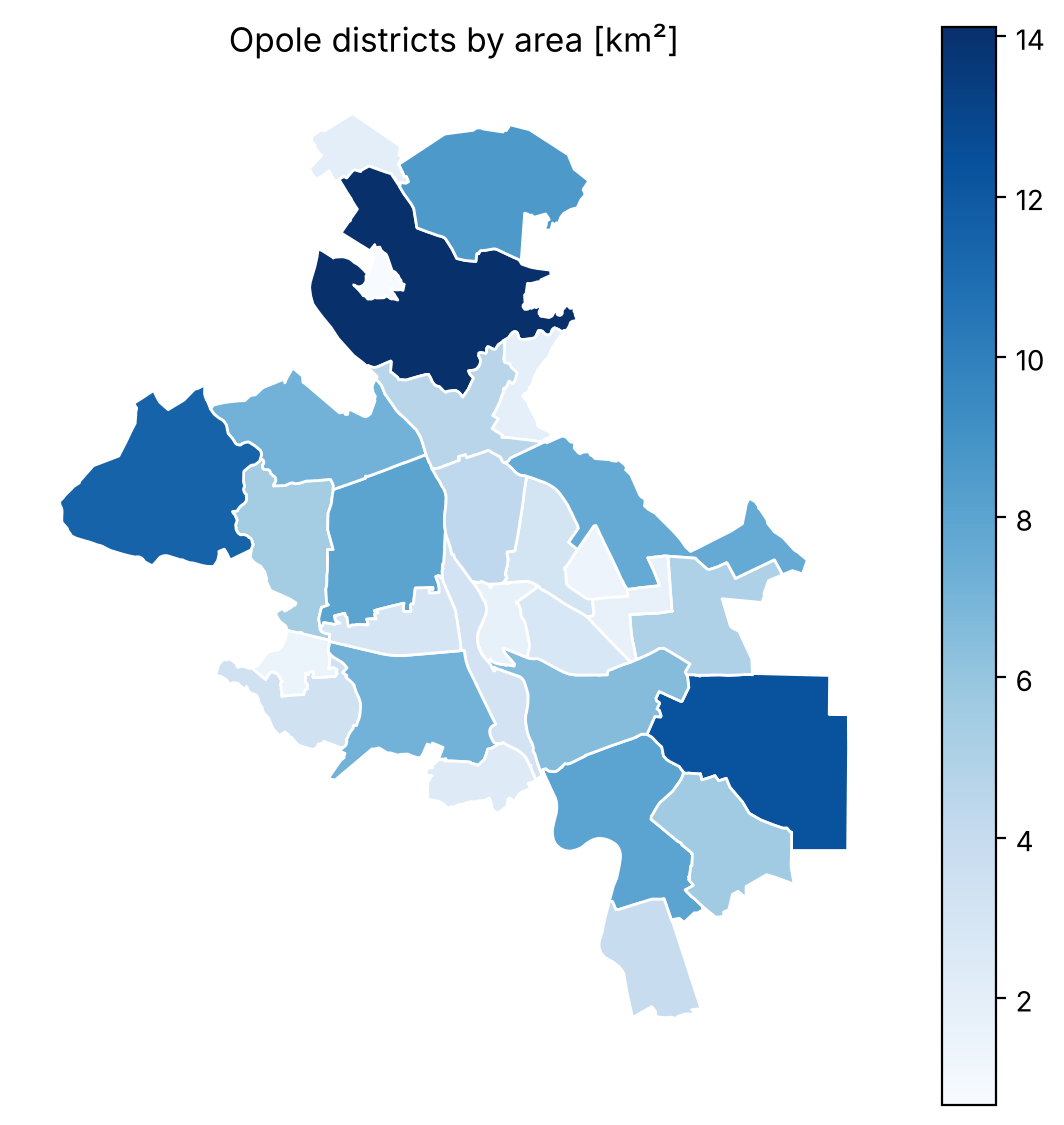

In [27]:
import matplotlib.pyplot as plt

ax = districts.plot(column="area_km2", cmap="Blues", legend=True,
                    edgecolor="white", figsize=(7, 7))
ax.set_title("Opole districts by area [km²]")
ax.set_axis_off()
plt.show()

🤔 **`.area` bez `to_crs`:** dostajemy powierzchnię w **stopniach kwadratowych** (dla całego miasta ok. 0,02).
Liczba nie ma sensownej jednostki, a „stopień²” nie ma stałej wielkości: stopień długości maleje z szerokością
(w Opolu ok. 70 km, na równiku ok. 111 km). GeoPandas widzi, że CRS jest geograficzny, i ostrzega
(*Geometry is in a geographic CRS. Results from 'area' are likely incorrect…*), żeby najpierw zrobić `to_crs` na układ rzutowany.

## A7. Złączenie przestrzenne

In [28]:
joined = gpd.sjoin(
    sensors_m,                                   # left: points
    districts[["name", "geometry"]],             # right: polygons (only the columns we need)
    how="left",
    predicate="within",                          # point lies within polygon
)
print(len(joined), joined["name"].isna().sum())
joined[["sensor_id", "pm25", "name"]].head()

130 0


,sensor_id,pm25,name
0,PM-042,23.5,Nadodrze
1,PM-106,12.4,Winów
2,PM-130,19.4,Grudzice
3,PM-025,16.8,Chabry
4,PM-137,14.4,Półwieś


In [29]:
stats = (joined.groupby("name")
               .agg(pm25_mean=("pm25", "mean"), sensor_count=("pm25", "size"))
               .round(1))

summary = districts.merge(stats, on="name", how="left")
summary.sort_values("pm25_mean", ascending=False).head()

,osm_id,name,geometry,area_km2,pm25_mean,sensor_count
18,9720720,Stare Miasto,"POLYGON ((423137.707 312629.565, 423286.828 31...",1.738654,29.6,3.0
26,9720881,Śródmieście,"POLYGON ((424619.006 312507.167, 424633.608 31...",2.805813,26.8,7.0
25,9721785,Zaodrze,"POLYGON ((419715.545 311574.778, 419778.921 31...",2.944668,22.5,6.0
15,9720000,Nadodrze,"POLYGON ((422466.331 312696.733, 422474.477 31...",3.168982,22.4,9.0
24,2730710,Zakrzów,"POLYGON ((422235.989 315159.897, 422390.296 31...",4.308565,20.8,13.0


In [30]:
print("dzielnice bez czujnika:", summary["pm25_mean"].isna().sum(), "->", summary.loc[summary["pm25_mean"].isna(), "name"].tolist())

dzielnice bez czujnika: 3 -> ['Bierkowice', 'Borki', 'Grotowice']


In [31]:
reliable = summary[summary["sensor_count"] >= 3]
reliable.nlargest(3, "pm25_mean")[["name", "pm25_mean", "sensor_count"]]

,name,pm25_mean,sensor_count
18,Stare Miasto,29.6,3.0
26,Śródmieście,26.8,7.0
25,Zaodrze,22.5,6.0


In [32]:
summary.explore(column="pm25_mean", cmap="Oranges", scheme="quantiles", k=5,
                legend_kwds={"caption": "mean PM2.5 [µg/m³]"},
                missing_kwds={"color": "lightgray", "label": "no sensors"})

In [33]:
# 🤔 within vs intersects
j2 = gpd.sjoin(sensors_m, districts[["name", "geometry"]], how="left", predicate="intersects")
print("intersects:", len(j2), "wierszy,", j2["name"].isna().sum(), "bez dzielnicy")
print("identyczne przypisanie:", (j2["name"].values == joined["name"].values).all())

intersects: 130 wierszy, 0 bez dzielnicy
identyczne przypisanie: True


🤔 **`intersects` zamiast `within`:** dla tych danych wynik jest identyczny. Punkt nie ma wnętrza, więc „leży w poligonie”
i „przecina poligon” różnią się tylko dla punktu **dokładnie na granicy**: `within` go nie złapie, `intersects` przypisze go do
obu sąsiednich dzielnic (zdubluje wiersz). Różnice pojawiłyby się też przy liniach lub poligonach po lewej stronie
(np. droga przechodząca przez 3 dzielnice: `intersects` złapie wszystkie trzy, `within` żadnej, bo nie leży cała w jednej).

## A8. Bufory

In [34]:
schools = gpd.read_file("dane/opole_schools.geojson").to_crs("EPSG:2180")

buffers = schools.copy()
buffers["geometry"] = schools.buffer(500)          # metres, because EPSG:2180
buffers.head(3)

,osm_id,name,geometry
0,way/207027259,Niepubliczna Szkoła Podstawowa Nasza Szkoła,"POLYGON ((425250.442 313309.464, 425248.034 31..."
1,way/208494323,Publiczna Szkoła Podstawowa nr 1 im. Obrońców ...,"POLYGON ((424964.042 311369.771, 424961.635 31..."
2,way/452471787,Publiczna Szkoła Podstawowa nr 10 im. Henryka ...,"POLYGON ((422845.594 310511.192, 422843.186 31..."


In [35]:
near_schools = gpd.sjoin(sensors_m, buffers[["name", "geometry"]], predicate="within")

print("schools:", len(schools))
print("schools with a sensor within 500 m:", near_schools["name"].nunique())
print(f"mean PM2.5 near schools: {near_schools['pm25'].mean():.1f} µg/m³")

schools: 19
schools with a sensor within 500 m: 11
mean PM2.5 near schools: 22.3 µg/m³


In [36]:
city = districts.union_all()
coverage = buffers.union_all().intersection(city).area / city.area
print(f"{coverage:.1%} of the city")

9.5% of the city


In [37]:
m = districts.explore(color="gray", style_kwds={"fillOpacity": 0.05}, name="districts")
buffers.explore(m=m, color="orange", name="500 m buffers")
sensors_m.explore(m=m, color="black", marker_kwds={"radius": 3}, name="sensors")
m

Ranking szkół (średnie PM2.5 z czujników w promieniu 500 m):

In [38]:
(near_schools.groupby("name")
             .agg(pm25_mean=("pm25", "mean"), sensor_count=("pm25", "size"))
             .round(1)
             .sort_values("pm25_mean", ascending=False))

,pm25_mean,sensor_count
name,,
Publiczna Szkoła Podstawowa nr 1 im. Obrońców Westerplatte,30.7,2
Publiczna Szkoła Podstawowa nr 21 im. Obrońców Pokoju,30.4,3
Publiczna Szkoła Podstawowa nr 2 im. Polskich Olimpijczyków,22.1,2
Szkoła Podstawowa nr 14,21.6,2
Niepubliczna Szkoła Podstawowa Nasza Szkoła,20.7,2
Szkoła Podstawowa nr 7,20.4,3
Publiczna Szkoła Podstawowa nr 10 im. Henryka Sienkiewicza,20.2,2
Publiczna Szkoła Podstawowa nr 5,19.3,1
Publiczna Szkoła Podstawowa nr 15,19.1,1


In [39]:
# 🤔 promień 1500 m
b1500 = schools.copy(); b1500["geometry"] = schools.buffer(1500)
n1500 = gpd.sjoin(sensors_m, b1500[["name", "geometry"]], predicate="within")
print("schools with a sensor within 1500 m:", n1500["name"].nunique(), "/", len(schools))

# i to samo w EPSG:4326 - jednostka to stopnie!
schools_deg = schools.to_crs("EPSG:4326")
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    bad = schools_deg.buffer(1500)
print("bounds bufora 1500 'stopni':", bad.total_bounds.round(1))

schools with a sensor within 1500 m: 19 / 19
bounds bufora 1500 'stopni': [-1482.1 -1449.4  1518.   1550.7]


🤔 **1500 m:** wszystkie 19 szkół mają czujnik w zasięgu.

**`buffer(1500)` w EPSG:4326** oznacza promień 1500 **stopni**, nie metrów. Współrzędne bufora wychodzą daleko poza
dopuszczalny zakres (bounds ok. −1480…1550, a długość ma tylko −180…180, szerokość −90…90). Taki „okrąg” obejmuje całą kulę
ziemską, więc każdy czujnik „jest blisko” każdej szkoły, a próba przeliczenia go do innego układu daje śmieci albo błędy. Nawet przy poprawnej wartości (np. 0,0135° ≈ 1,5 km) bufor w stopniach byłby elipsą,
bo stopień długości w Opolu ma ok. 70 km, a stopień szerokości ok. 111 km. Bufory zawsze liczymy w układzie metrycznym.

## A9. Zapis wyników

In [40]:
from pathlib import Path

out = Path("wyniki")
out.mkdir(exist_ok=True)

# GeoPackage: many layers in one file, any CRS - the default choice
summary.to_file(out / "pm25.gpkg", layer="districts", driver="GPKG")
sensors_m.to_file(out / "pm25.gpkg", layer="sensors", driver="GPKG")

# GeoJSON: for web applications - always save it in EPSG:4326
summary.to_crs("EPSG:4326").to_file(out / "pm25_districts.geojson", driver="GeoJSON")

gpd.list_layers(out / "pm25.gpkg")

,name,geometry_type
0,districts,Polygon
1,sensors,Point


In [41]:
check = gpd.read_file(out / "pm25.gpkg", layer="districts")
print(len(check), check.crs)

29 EPSG:2180


## Podsumowanie

| Pytanie | Odpowiedź |
|---|---|
| Najgorsze powietrze (dzielnice z ≥3 czujnikami) | **Stare Miasto 29,6**, Śródmieście 26,8, Zaodrze 22,5 µg/m³ |
| Dzielnice bez czujnika | 3 (patrz A7) |
| Szkoły z czujnikiem ≤500 m | 11 z 19, średnie PM2.5 ok. 22,3 µg/m³ |
| Zasięg buforów 500 m | ok. 9,5% powierzchni miasta |

Schemat: `read_csv → czyszczenie → GeoDataFrame → to_crs → read_file → sjoin / buffer → to_file`.